<a href="https://colab.research.google.com/github/SupriyaPathak-04/retailpulse-analytics/blob/main/bigdata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np


In [3]:
pip install ucimlrepo

In [4]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
X = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)


{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [5]:

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
#inspecting the dataset
print("number of rows and col: ",df.shape)
print("\n name of the columns")
print(df.columns)
print("\n dataset information")
df.info()
df.isnull().sum()

number of rows and col:  (541909, 8)

 name of the columns
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

 dataset information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [7]:
#finding the duplicate value in the dataset
duplicate = df.duplicated().sum()
print(duplicate)

5268


In [8]:
duplicates = df[df.duplicated()]
display(duplicates.head(10))

print("index of the duplicate value: \n")
duplicate_indexes = df.index[df.duplicated()]


idx = duplicate_indexes[0]
display(df.loc[[idx-1, idx]])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


index of the duplicate value: 



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
516,536409,22075,6 RIBBONS ELEGANT CHRISTMAS,1,2010-12-01 11:45:00,1.65,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom


In [9]:
# Verify that these rows exactly match an earlier occurrence
display(df[df.duplicated(keep=False)].sort_values(
    list(df.columns)
).head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [10]:
#removing the duplicate values from the database and creating a new dataset for the further processing
df_clean = df.drop_duplicates().copy()
print("original rows: ",len(df))
print("after removal: ",len(df_clean))
print("duplicate remaining: ",df_clean.duplicated().sum())

original rows:  541909
after removal:  536641
duplicate remaining:  0


In [11]:
#handling the cancellation in the dataset
cancellation = df_clean["InvoiceNo"].astype(str).str.startswith("C")
print("cancellation rows : ",cancellation.sum())
print("non cancellation rows : ",(~cancellation).sum())


cancellation rows :  9251
non cancellation rows :  527390


In [12]:
print("zero and negative quantities rows : ",(df_clean["Quantity"]<=0).sum())
print("zero and negative unit price  rows : ",(df_clean["UnitPrice"]<=0).sum())


zero and negative quantities rows :  10587
zero and negative unit price  rows :  2512


In [13]:
unusual_qty = df_clean[df_clean["Quantity"]<=0]

print("total rows with quantity<=0: ",len(unusual_qty))

display(unusual_qty[["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]].head(10))


total rows with quantity<=0:  10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0


In [14]:
#comapring the cancellation and the negative quantity values
cancellation = df_clean["InvoiceNo"].astype(str).str.startswith("C")
negative_qty = df_clean["Quantity"]<0

print("cancellation rows: ",cancellation.sum())
print("Negative qty: ",negative_qty.sum())

print("Negative qty rows without c invoice: ",(negative_qty & ~cancellation).sum())

cancellation rows:  9251
Negative qty:  10587
Negative qty rows without c invoice:  1336


In [15]:
#inspecting the negative quantity without C invoice
negative_qty1 = df_clean[(df_clean["Quantity"]<0) & (~cancellation)]

print("Rows to investigate :",len(negative_qty1))

display(
    negative_qty1[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
    ].head(10)
)

Rows to investigate : 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN


In [16]:
print("Zero-price rows:",
      (negative_qty1["UnitPrice"] == 0).sum())

print("Missing descriptions:",
      negative_qty1["Description"].isna().sum())

print("Missing customer IDs:",
      negative_qty1["CustomerID"].isna().sum())

Zero-price rows: 1336
Missing descriptions: 862
Missing customer IDs: 1336


In [17]:
# Investigate non-positive unit prices
nonpositive_price = df_clean[df_clean["UnitPrice"] <= 0]

print("Total rows with non-positive prices:", len(nonpositive_price))
print("Zero-price rows:", (nonpositive_price["UnitPrice"] == 0).sum())
print("Negative-price rows:", (nonpositive_price["UnitPrice"] < 0).sum())

display(
    nonpositive_price[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID"]
    ].head(10)
)

Total rows with non-positive prices: 2512
Zero-price rows: 2510
Negative-price rows: 2


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.0,NaN
1970,536545,21134,NaN,1,0.0,NaN
1971,536546,22145,NaN,1,0.0,NaN
1972,536547,37509,NaN,1,0.0,NaN
1987,536549,85226A,NaN,1,0.0,NaN
1988,536550,85044,NaN,1,0.0,NaN
2024,536552,20950,NaN,1,0.0,NaN
2025,536553,37461,NaN,3,0.0,NaN
2026,536554,84670,NaN,23,0.0,NaN
2406,536589,21777,NaN,-10,0.0,NaN


In [18]:
# Inspect the two negative-price records
negative_price = df_clean[df_clean["UnitPrice"] < 0]

display(
    negative_price[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
    ]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN


## Data Quality Finding: Negative Unit Prices

Two records have negative unit prices of -11062.06 and the description "Adjust bad debt".
These appear to be accounting adjustments rather than ordinary product sales.
Decision: Exclude these records from product-sales revenue calculations and customer purchase modelling. Preserve the original records for traceability.
Reason: Including accounting adjustments as product sales could distort revenue and customer behaviour metrics.
Validation:Confirm the two records are excluded from the analysis-specific sales dataset.

In [19]:
#creating the new dataframe for the sales analysis

sales_df = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C")) &
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Deduplicated rows:", len(df_clean))
print("Sales rows:", len(sales_df))
print("Rows excluded:", len(df_clean) - len(sales_df))

Deduplicated rows: 536641
Sales rows: 524878
Rows excluded: 11763


In [20]:
#Check customer ID completeness
missing_customers = sales_df["CustomerID"].isnull().sum()
total_rows = len(sales_df)

print("Total sales rows:", total_rows)
print("Rows with missing CustomerID:", missing_customers)
print("Percentage missing:", round(missing_customers / total_rows * 100, 2), "%")

Total sales rows: 524878
Rows with missing CustomerID: 132186
Percentage missing: 25.18 %


In [21]:
#Create a dataset for customer-level analysis
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

print("Customer dataset rows:", len(customer_df))
print("Missing customer IDs:", customer_df["CustomerID"].isnull().sum())
print("Unique customers:", customer_df["CustomerID"].nunique())

Customer dataset rows: 392692
Missing customer IDs: 0
Unique customers: 4338


In [22]:
#before revenue calculation validating and understanding the sales data

print("Missing invoice dates:", sales_df["InvoiceDate"].isnull().sum())
print("Zero or negative quantities:", (sales_df["Quantity"] <= 0).sum())
print("Zero or negative prices:", (sales_df["UnitPrice"] <= 0).sum())

Missing invoice dates: 0
Zero or negative quantities: 0
Zero or negative prices: 0


##In this dataset, each row represents a product line in an invoice, so its revenue is:

##Revenue = Quantity*UnitPrice


In [23]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Total revenue:", round(sales_df["Revenue"].sum(), 2))
display(sales_df[["InvoiceNo", "Description", "Quantity", "UnitPrice", "Revenue"]].head(10))

Total revenue: 10642110.8


,InvoiceNo,Description,Quantity,UnitPrice,Revenue
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,WHITE METAL LANTERN,6,3.39,20.34
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,536366,HAND WARMER UNION JACK,6,1.85,11.10
8,536366,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [24]:
#extracting the month from InvoiceDate and calculate revenue by month.
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")
monthly_revenue = sales_df.groupby("Month")["Revenue"].sum()
display(monthly_revenue)


,Revenue
Month,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


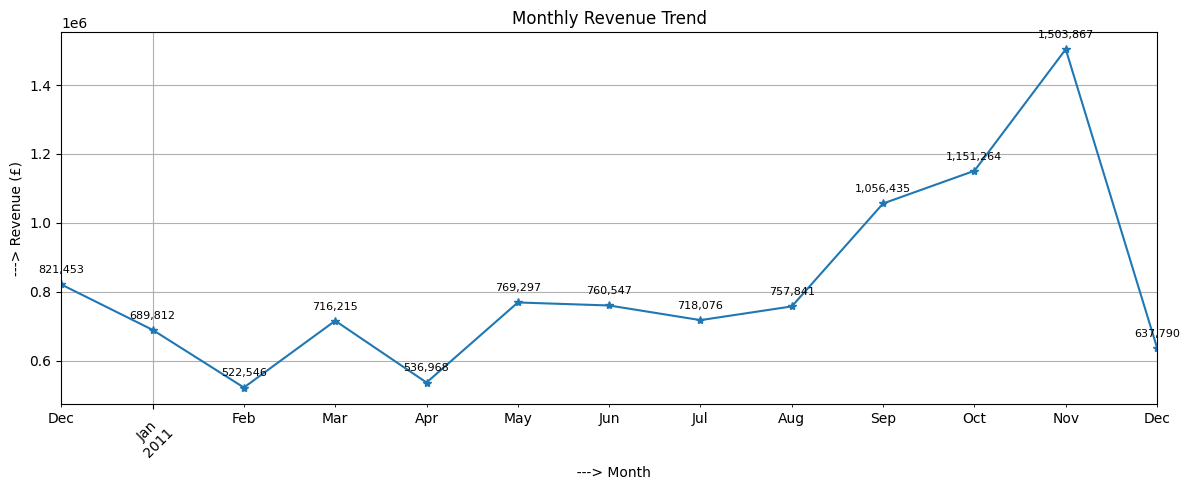

In [25]:
import matplotlib.pyplot as plt

monthly_revenue.plot(kind="line", marker="*", figsize=(12, 5))


# Display the revenue value at each point
for month, revenue in zip(monthly_revenue.index.astype(str), monthly_revenue.values):
    plt.annotate(f"{revenue:,.0f}",
                 (month, revenue),
                 textcoords="offset points",
                 xytext=(0, 8),
                 ha="center",
                 fontsize=8)

plt.title("Monthly Revenue Trend")
plt.xlabel("  ---> Month")
plt.ylabel("---> Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
monthly_orders = sales_df.groupby("Month")["InvoiceNo"].nunique()

monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Unique_Orders": monthly_orders
})

display(monthly_analysis)

,Revenue,Unique_Orders
Month,,
2010-12,821452.730,1559
2011-01,689811.610,1086
2011-02,522545.560,1100
2011-03,716215.260,1454
2011-04,536968.491,1246
2011-05,769296.610,1681
2011-06,760547.010,1533
2011-07,718076.121,1475
2011-08,757841.380,1361


In [27]:
monthly_analysis["Revenue_per_Order"] = (
    monthly_analysis["Revenue"] / monthly_analysis["Unique_Orders"]
)

display(monthly_analysis[["Revenue", "Unique_Orders", "Revenue_per_Order"]].round(2))

,Revenue,Unique_Orders,Revenue_per_Order
Month,,,
2010-12,821452.73,1559,526.91
2011-01,689811.61,1086,635.19
2011-02,522545.56,1100,475.04
2011-03,716215.26,1454,492.58
2011-04,536968.49,1246,430.95
2011-05,769296.61,1681,457.64
2011-06,760547.01,1533,496.12
2011-07,718076.12,1475,486.83
2011-08,757841.38,1361,556.83


In [28]:
highest_month = monthly_analysis["Revenue"].idxmax()
lowest_month = monthly_analysis["Revenue"].idxmin()

print("Highest revenue month:", highest_month)
print("Highest revenue:", round(monthly_analysis.loc[highest_month, "Revenue"], 2))

print("Lowest revenue month:", lowest_month)
print("Lowest revenue:", round(monthly_analysis.loc[lowest_month, "Revenue"], 2))

Highest revenue month: 2011-11
Highest revenue: 1503866.78
Lowest revenue month: 2011-02
Lowest revenue: 522545.56


In [29]:
#top selling product
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending= False)
    .head(10)
)

display(top_products)

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
JUMBO BAG RED RETROSPOT,48371
WHITE HANGING HEART T-LIGHT HOLDER,37872
POPCORN HOLDER,36749
PACK OF 72 RETROSPOT CAKE CASES,36396
ASSORTED COLOUR BIRD ORNAMENT,36362
RABBIT NIGHT LIGHT,30739


In [30]:
#highest revenue generating product
top_revenue_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_revenue_products)

,Revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


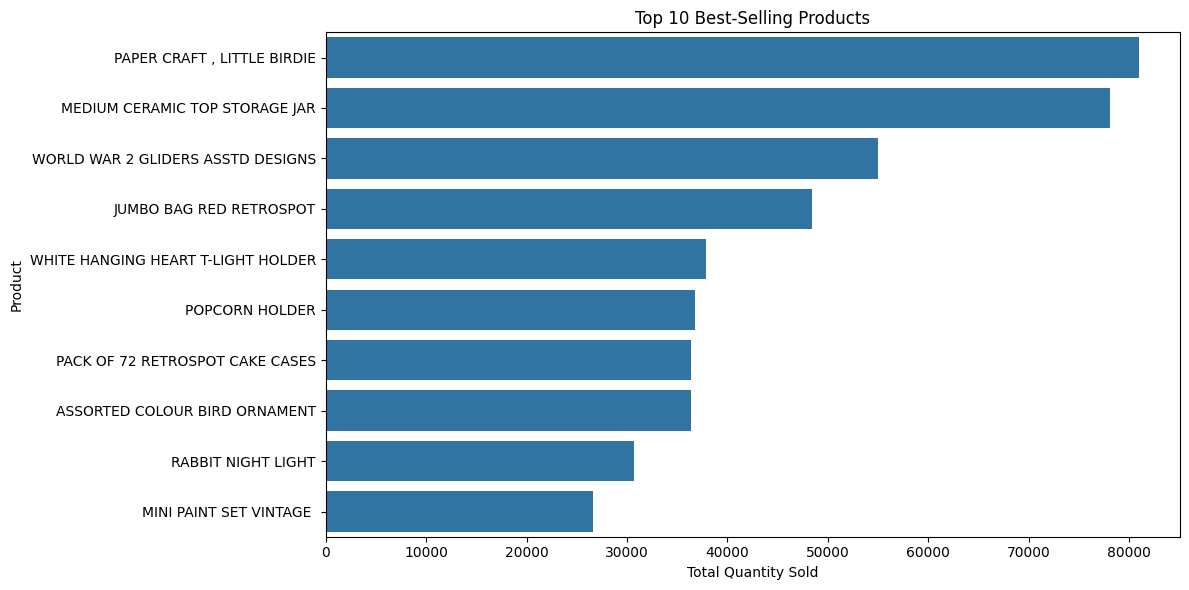

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find the 10 products with the highest total quantity sold
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Plot the results
plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [31]:
#revenue by country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

display(country_revenue.head(10))

,Revenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


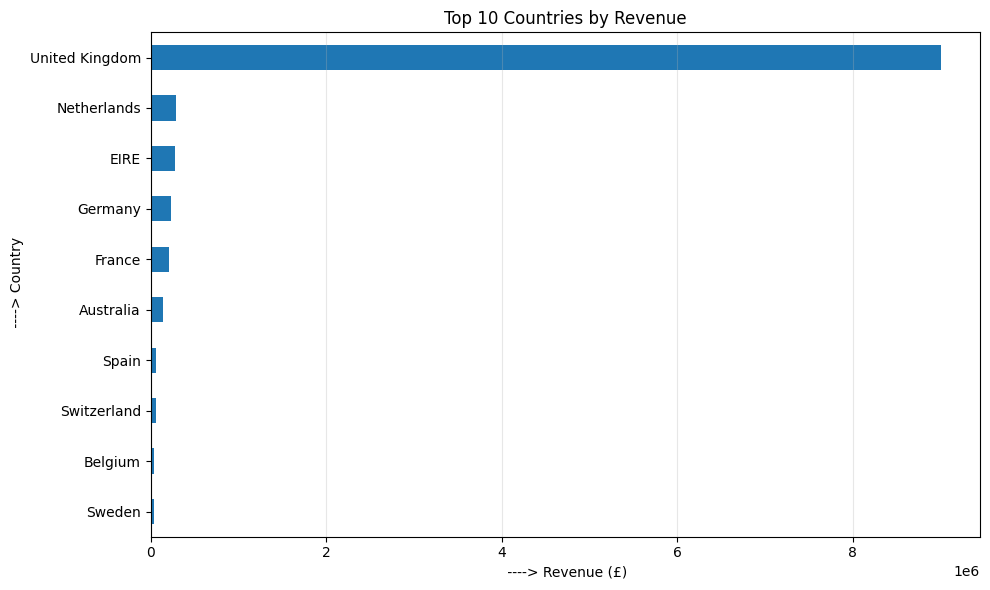

In [32]:
top_countries = country_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_countries.plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel(" ----> Revenue (£)")
plt.ylabel(" ----> Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
#monthly order analysis
monthly_orders = (
    sales_df.groupby("Month")["InvoiceNo"]
    .nunique()
)

display(monthly_orders)

,InvoiceNo
Month,
2010-12,1559
2011-01,1086
2011-02,1100
2011-03,1454
2011-04,1246
2011-05,1681
2011-06,1533
2011-07,1475
2011-08,1361


In [34]:
#cheching if the month with higher order generates the highestest revenue
monthly_analysis = pd.DataFrame({
    "Revenue": monthly_revenue,
    "Unique_Orders": monthly_orders
})

monthly_analysis["Revenue_per_Order"] = (
    monthly_analysis["Revenue"] /
    monthly_analysis["Unique_Orders"]
)

display(monthly_analysis.round(2))

,Revenue,Unique_Orders,Revenue_per_Order
Month,,,
2010-12,821452.73,1559,526.91
2011-01,689811.61,1086,635.19
2011-02,522545.56,1100,475.04
2011-03,716215.26,1454,492.58
2011-04,536968.49,1246,430.95
2011-05,769296.61,1681,457.64
2011-06,760547.01,1533,496.12
2011-07,718076.12,1475,486.83
2011-08,757841.38,1361,556.83


In [35]:
print("Unique customers:", sales_df["CustomerID"].nunique())
print("Unique orders:", sales_df["InvoiceNo"].nunique())
print("Date range:")
print(sales_df["InvoiceDate"].min())
print(sales_df["InvoiceDate"].max())

Unique customers: 4338
Unique orders: 19960
Date range:
2010-12-01 08:26:00
2011-12-09 12:50:00


Average orders per customer: 4.27
Median orders per customer: 2.0
Minimum orders: 1
Maximum orders: 209


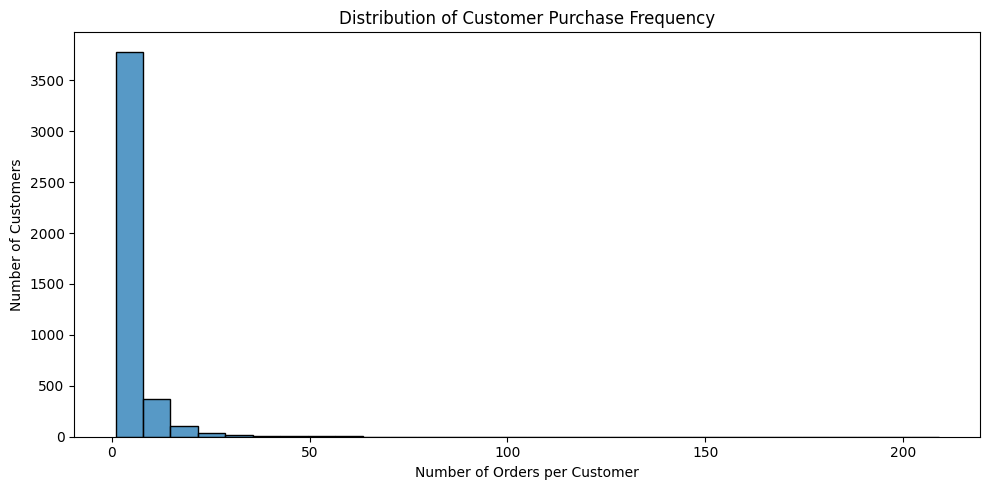

In [71]:
# Count distinct orders for each customer
customer_frequency = (
    sales_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print("Average orders per customer:",
      round(customer_frequency.mean(), 2))

print("Median orders per customer:",
      customer_frequency.median())

print("Minimum orders:",
      customer_frequency.min())

print("Maximum orders:",
      customer_frequency.max())


# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(customer_frequency, bins=30)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [37]:
# Count customers by their number of orders
order_frequency_distribution = (
    customer_frequency.value_counts()
    .sort_index()
)

display(order_frequency_distribution)

,count
InvoiceNo,
1,1493
2,835
3,508
4,388
5,242
6,172
7,143
8,98
9,68


In [38]:
one_order_customers = (customer_frequency == 1).sum()

total_customers = customer_frequency.count()

one_order_percentage = (
    one_order_customers / total_customers * 100
)

print("Customers with one order:", one_order_customers)
print("Total customers:", total_customers)
print("One-order customer percentage:",
      round(one_order_percentage, 2), "%")

Customers with one order: 1493
Total customers: 4338
One-order customer percentage: 34.42 %


In [39]:
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

In [40]:
#calculating customer spending during the obsevation period
customer_analysis = (
    customer_df.groupby("CustomerID")
    .agg(
        Total_Orders=("InvoiceNo", "nunique"),
        Total_Spending=("Revenue", "sum")
    )
)

customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Spending"]
    / customer_analysis["Total_Orders"]
)

display(
    customer_analysis
    .sort_values("Total_Spending", ascending=False)
    .head(10)
    .round(2)
)

,Total_Orders,Total_Spending,Average_Order_Value
CustomerID,,,
14646.0,73,280206.02,3838.44
18102.0,60,259657.30,4327.62
17450.0,46,194390.79,4225.89
16446.0,2,168472.50,84236.25
14911.0,201,143711.17,714.98
12415.0,21,124914.53,5948.31
14156.0,55,117210.08,2131.09
17511.0,31,91062.38,2937.50
16029.0,63,80850.84,1283.35


In [41]:
print("Customers with the most orders:")
display(
    customer_analysis
    .sort_values("Total_Orders", ascending=False)
    .head(10)
    .round(2)
)

Customers with the most orders:


,Total_Orders,Total_Spending,Average_Order_Value
CustomerID,,,
12748.0,209,33053.19,158.15
14911.0,201,143711.17,714.98
17841.0,124,40519.84,326.77
13089.0,97,58762.08,605.79
14606.0,93,12076.15,129.85
15311.0,91,60632.75,666.29
12971.0,86,11189.91,130.12
14646.0,73,280206.02,3838.44
16029.0,63,80850.84,1283.35


In [42]:
# Summarize customer spending by purchase frequency
frequency_summary = (
    customer_analysis
    .groupby("Total_Orders")
    .agg(
        Customer_Count=("Total_Spending", "size"),
        Average_Spending=("Total_Spending", "mean"),
        Average_Order_Value=("Average_Order_Value", "mean")
    )
)

display(frequency_summary.head(10).round(2))

,Customer_Count,Average_Spending,Average_Order_Value
Total_Orders,,,
1,1493,411.25,411.25
2,835,883.19,441.60
3,508,1277.80,425.93
4,388,1428.26,357.07
5,242,1811.88,362.38
6,172,2405.18,400.86
7,143,2875.92,410.85
8,98,3011.11,376.39
9,68,3142.01,349.11


In [43]:
c_invoices = sales_df[
    sales_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Rows with C invoices:", len(c_invoices))
print("Unique C invoices:", c_invoices["InvoiceNo"].nunique())

Rows with C invoices: 0
Unique C invoices: 0


In [44]:
negative_quantity = sales_df[sales_df["Quantity"] < 0]

print("Rows with negative quantity:", len(negative_quantity))

Rows with negative quantity: 0


In [45]:
negative_price = sales_df[sales_df["UnitPrice"] < 0]

print("Rows with negative unit price:", len(negative_price))

Rows with negative unit price: 0


In [46]:
print("df_clean shape:", df_clean.shape)
print("sales_df shape:", sales_df.shape)

df_clean shape: (536641, 8)
sales_df shape: (524878, 10)


In [47]:
print("First transaction:", sales_df["InvoiceDate"].min())
print("Last transaction:", sales_df["InvoiceDate"].max())

First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


In [48]:
reference_date = sales_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

customer_recency = (
    sales_df.groupby("CustomerID")["InvoiceDate"]
    .max()
    .apply(lambda date: (reference_date - date).days)
)
display(customer_recency.head(10))

,InvoiceDate
CustomerID,
12346.0,325
12347.0,2
12348.0,75
12349.0,18
12350.0,310
12352.0,36
12353.0,204
12354.0,232
12355.0,214


In [49]:
customer_summary = pd.DataFrame({
    "Recency": customer_recency,
    "Frequency": customer_frequency
})

display(customer_summary.head(10))

,Recency,Frequency
CustomerID,,
12346.0,325,1
12347.0,2,7
12348.0,75,4
12349.0,18,1
12350.0,310,1
12352.0,36,8
12353.0,204,1
12354.0,232,1
12355.0,214,1


In [50]:
customer_monetary = (
    sales_df.groupby("CustomerID")["Revenue"]
    .sum()
)

customer_summary["Monetary"] = customer_monetary

display(customer_summary.head(10))

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,18,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [51]:
top_customers = customer_summary.sort_values(
    "Monetary",
    ascending=False
).head(10)

display(top_customers)

,Recency,Frequency,Monetary
CustomerID,,,
14646.0,1,73,280206.02
18102.0,0,60,259657.30
17450.0,8,46,194390.79
16446.0,0,2,168472.50
14911.0,1,201,143711.17
12415.0,24,21,124914.53
14156.0,9,55,117210.08
17511.0,2,31,91062.38
16029.0,38,63,80850.84


In [52]:
#checking the customer who spend the most
sales_df[sales_df["CustomerID"] == 16446][
    ["InvoiceNo", "InvoiceDate", "Description", "Quantity", "UnitPrice", "Revenue"]
].sort_values("Revenue", ascending=False)

,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,Revenue
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
194354,553573,2011-05-18 09:52:00,PANTRY SCRUBBING BRUSH,1,1.65,1.65
194355,553573,2011-05-18 09:52:00,PANTRY PASTRY BRUSH,1,1.25,1.25


In [53]:
df_clean[
    (df_clean["CustomerID"] == 16446) &
    (df_clean["StockCode"] == "23843")
][
    ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"]
]

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID


In [54]:
display(df_clean["StockCode"].dtype)

display(
    df_clean.loc[
        df_clean["InvoiceNo"].astype(str) == "581483",
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "CustomerID"]
    ]
)

dtype('O')

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0


In [55]:
# Check the full transaction record
display(
    df_clean.loc[
        df_clean["InvoiceNo"].astype(str) == "581483"
    ]
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [56]:
display(customer_summary.head())
print("Customer summary shape:", customer_summary.shape)
print("Missing values:")
print(customer_summary.isnull().sum())

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,18,1,1757.55
12350.0,310,1,334.40


Customer summary shape: (4338, 3)
Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [57]:
display(customer_summary.describe().round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.06,4.27,2048.69
std,100.01,7.70,8985.23
min,0.00,1.00,3.75
25%,17.00,1.00,306.48
50%,50.00,2.00,668.57
75%,141.75,5.00,1660.60
max,373.00,209.00,280206.02


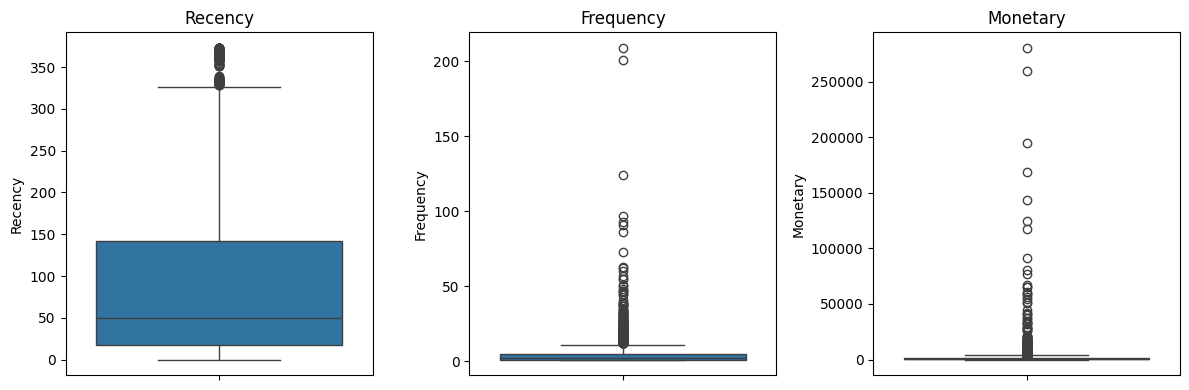

In [58]:
import seaborn as sns

plt.figure(figsize=(12, 4))

for i, column in enumerate(
    ["Recency", "Frequency", "Monetary"], start=1
):
    plt.subplot(1, 3, i)
    sns.boxplot(y=customer_summary[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [59]:
reference_date = sales_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

customer_recency = (
    sales_df.groupby("CustomerID")["InvoiceDate"]
    .max()
    .apply(lambda date: (reference_date - date).days)
)

In [60]:
customer_summary.sort_values(
    "Monetary",
    ascending=False
).head(10)

,Recency,Frequency,Monetary
CustomerID,,,
14646.0,1,73,280206.02
18102.0,0,60,259657.30
17450.0,8,46,194390.79
16446.0,0,2,168472.50
14911.0,1,201,143711.17
12415.0,24,21,124914.53
14156.0,9,55,117210.08
17511.0,2,31,91062.38
16029.0,38,63,80850.84


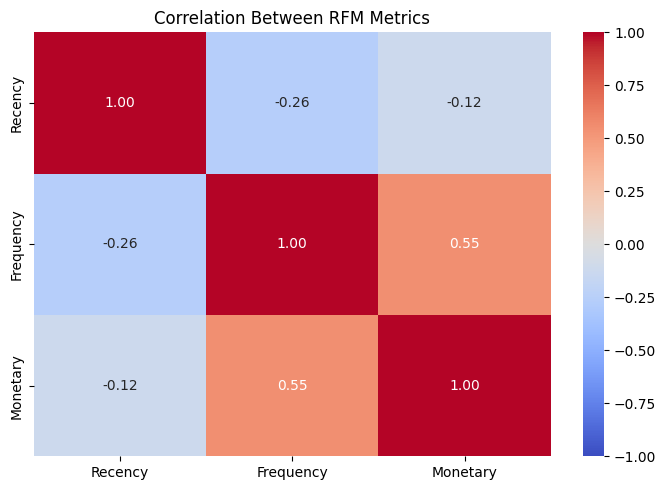

In [72]:
rfm_corr = customer_summary[
    ["Recency", "Frequency", "Monetary"]
].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    rfm_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between RFM Metrics")
plt.tight_layout()
plt.show()

In [61]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Prepare RFM features
rfm = customer_summary[["Recency", "Frequency", "Monetary"]].copy()

# Scale the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

print("RFM data shape:", rfm.shape)
print("Scaled data shape:", rfm_scaled.shape)

RFM data shape: (4338, 3)
Scaled data shape: (4338, 3)


In [63]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

customer_summary["Cluster"] = kmeans.fit_predict(rfm_scaled)

print(customer_summary["Cluster"].value_counts().sort_index())

Cluster
0    3060
1    1061
2      13
3     204
Name: count, dtype: int64


In [64]:
cluster_summary = customer_summary.groupby("Cluster").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(cluster_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,3060,43.43,3.68,1352.75
1,1061,248.17,1.55,476.42
2,13,6.62,82.54,127187.96
3,204,14.96,22.33,12690.50


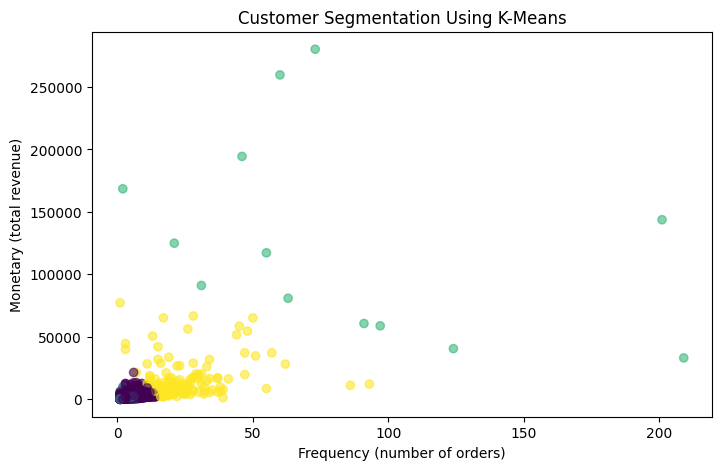

In [65]:
#Visualization Of the k-mean clustering
plt.figure(figsize=(8, 5))

plt.scatter(
    customer_summary["Frequency"],
    customer_summary["Monetary"],
    c=customer_summary["Cluster"],
    alpha=0.6
)

plt.xlabel("Frequency (number of orders)")
plt.ylabel("Monetary (total revenue)")
plt.title("Customer Segmentation Using K-Means")
plt.show()

In [67]:
#predictive model
# Ensure dates are in datetime format
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

# Define the split date
split_date = sales_df["InvoiceDate"].max() - pd.DateOffset(months=2)

# Use earlier transactions to build customer features
past_data = sales_df[sales_df["InvoiceDate"] < split_date].copy()

# Use later transactions to identify future purchases
future_data = sales_df[sales_df["InvoiceDate"] >= split_date].copy()

# Historical customer features
features = past_data.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (split_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

# Target: did the customer purchase during the future period?
future_customers = future_data["CustomerID"].dropna().unique()

features["PurchasedLater"] = features.index.isin(future_customers).astype(int)

print("Feature dataset shape:", features.shape)
print("\nTarget distribution:")
print(features["PurchasedLater"].value_counts())

Feature dataset shape: (3710, 4)

Target distribution:
PurchasedLater
0    1916
1    1794
Name: count, dtype: int64


In [68]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Remove any rows with missing feature values
features = features.dropna()

X = features[["Recency", "Frequency", "Monetary"]]
y = features["PurchasedLater"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

model.fit(X_train, y_train)

# Predict on unseen test customers
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.668

Confusion Matrix:
[[302  81]
 [165 194]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.79      0.71       383
           1       0.71      0.54      0.61       359

    accuracy                           0.67       742
   macro avg       0.68      0.66      0.66       742
weighted avg       0.68      0.67      0.66       742



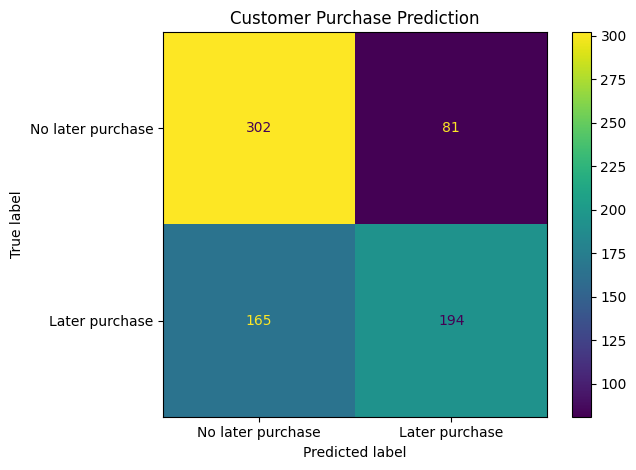

In [69]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No later purchase", "Later purchase"]
)

plt.title("Customer Purchase Prediction")
plt.tight_layout()
plt.show()